# Playground Series S6E9 — Modeling

Baseline (Logistic Regression) → Gradient Boosting (LightGBM, XGBoost), 5-fold stratified
CV on ROC-AUC (imbalanced binary target, ~17.5% positive).


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import xgboost as xgb

train = pd.read_parquet("../data/train_features.parquet")
test = pd.read_parquet("../data/test_features.parquet")

target = "Will_Buy_EV_bin"
feature_cols = [c for c in train.columns if c != target]
X, y = train[feature_cols], train[target]
X_test = test[feature_cols]

X.shape, y.mean()


((668665, 20), np.float64(0.17464500160768098))

## Baseline: Logistic Regression

In [2]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_scores = []
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_val_s = scaler.transform(X_val)

    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    model.fit(X_tr_s, y_tr)
    preds = model.predict_proba(X_val_s)[:, 1]
    auc = roc_auc_score(y_val, preds)
    lr_scores.append(auc)
    print(f"Fold {fold}: AUC={auc:.5f}")

print(f"\nLogistic Regression mean AUC: {np.mean(lr_scores):.5f} (+/- {np.std(lr_scores):.5f})")


Fold 0: AUC=0.93671


Fold 1: AUC=0.93808


Fold 2: AUC=0.93913


Fold 3: AUC=0.93866


Fold 4: AUC=0.93812

Logistic Regression mean AUC: 0.93814 (+/- 0.00081)


## LightGBM

In [3]:
lgb_scores = []
lgb_models = []
oof_lgb = np.zeros(len(X))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
    )
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    preds = model.predict_proba(X_val)[:, 1]
    oof_lgb[val_idx] = preds
    auc = roc_auc_score(y_val, preds)
    lgb_scores.append(auc)
    lgb_models.append(model)
    print(f"Fold {fold}: AUC={auc:.5f} (best_iter={model.best_iteration_})")

print(f"\nLightGBM mean AUC: {np.mean(lgb_scores):.5f} (+/- {np.std(lgb_scores):.5f})")
print(f"LightGBM OOF AUC: {roc_auc_score(y, oof_lgb):.5f}")


/Users/anilturan/.venvs/kaggle-competition-solutions/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 0: AUC=0.94030 (best_iter=1000)


/Users/anilturan/.venvs/kaggle-competition-solutions/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: AUC=0.94134 (best_iter=1000)


/Users/anilturan/.venvs/kaggle-competition-solutions/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: AUC=0.94278 (best_iter=1000)


/Users/anilturan/.venvs/kaggle-competition-solutions/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: AUC=0.94218 (best_iter=1000)


/Users/anilturan/.venvs/kaggle-competition-solutions/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: AUC=0.94164 (best_iter=999)

LightGBM mean AUC: 0.94165 (+/- 0.00084)
LightGBM OOF AUC: 0.94164


## XGBoost

In [4]:
scale_pos_weight = (y == 0).sum() / (y == 1).sum()
xgb_scores = []
xgb_models = []
oof_xgb = np.zeros(len(X))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    model = xgb.XGBClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=6,
        scale_pos_weight=scale_pos_weight,
        eval_metric="auc",
        early_stopping_rounds=50,
        random_state=42,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    preds = model.predict_proba(X_val)[:, 1]
    oof_xgb[val_idx] = preds
    auc = roc_auc_score(y_val, preds)
    xgb_scores.append(auc)
    xgb_models.append(model)
    print(f"Fold {fold}: AUC={auc:.5f} (best_iter={model.best_iteration})")

print(f"\nXGBoost mean AUC: {np.mean(xgb_scores):.5f} (+/- {np.std(xgb_scores):.5f})")
print(f"XGBoost OOF AUC: {roc_auc_score(y, oof_xgb):.5f}")


Fold 0: AUC=0.94036 (best_iter=679)


Fold 1: AUC=0.94121 (best_iter=581)


Fold 2: AUC=0.94276 (best_iter=856)


Fold 3: AUC=0.94220 (best_iter=804)


Fold 4: AUC=0.94163 (best_iter=629)

XGBoost mean AUC: 0.94163 (+/- 0.00082)


XGBoost OOF AUC: 0.94162


## Model comparison & feature importance

                 model  mean_auc   std_auc
0  Logistic Regression  0.938140  0.000812
1             LightGBM  0.941648  0.000837
2              XGBoost  0.941631  0.000823

Best model: LightGBM


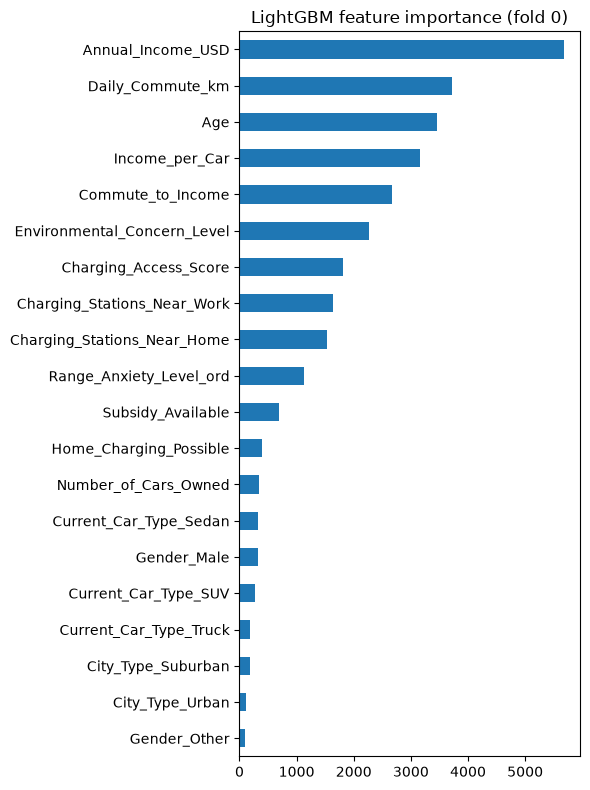

In [5]:
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "model": ["Logistic Regression", "LightGBM", "XGBoost"],
    "mean_auc": [np.mean(lr_scores), np.mean(lgb_scores), np.mean(xgb_scores)],
    "std_auc": [np.std(lr_scores), np.std(lgb_scores), np.std(xgb_scores)],
})
print(comparison)

best_model_name = comparison.loc[comparison["mean_auc"].idxmax(), "model"]
print(f"\nBest model: {best_model_name}")

importances = pd.Series(lgb_models[0].feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(6, 8))
importances.head(20).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("LightGBM feature importance (fold 0)")
plt.tight_layout()
plt.show()


## Final fit on full data & submission (best model)

In [6]:
# Average the fold models' test predictions (bagging across CV folds)
test_preds_lgb = np.mean([m.predict_proba(X_test)[:, 1] for m in lgb_models], axis=0)
test_preds_xgb = np.mean([m.predict_proba(X_test)[:, 1] for m in xgb_models], axis=0)

# use whichever had the higher OOF AUC
final_preds = test_preds_lgb if roc_auc_score(y, oof_lgb) >= roc_auc_score(y, oof_xgb) else test_preds_xgb

submission = pd.DataFrame({"id": test["id"], "Will_Buy_EV": final_preds})
submission.to_csv("../submissions/submission_v1.csv", index=False)
submission.head()


,id,Will_Buy_EV
0,668665,0.041768
1,668666,0.094707
2,668667,0.020754
3,668668,0.014180
4,668669,0.074917


## Key Takeaways

- Gradient boosting (LightGBM/XGBoost) captures nonlinear feature interactions that the
  logistic regression baseline misses — compare mean AUC above to quantify the lift.
- 5-fold CV with `class_weight="balanced"` / `scale_pos_weight` handles the ~17.5% positive
  class imbalance without resampling.
- Next iteration: Optuna hyperparameter search on the better of the two boosters, then
  blend LightGBM + XGBoost predictions instead of picking one.
